UTS GRAF SAINS DATA 
Nama : Thea Bayu Revalina
Nim : 23031554035
Kelas : 2023A 

2.1 WRANGLING DAN EDA 

1. Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yg dipilih per individu tidak
boleh sama dalam 1 kelas.
Misal: Fold training (P1) → 01/2023 - 03/2023; Fold testing (P2) 01/2024 - 06/2024. 

Jawab : 
Periode yang digunakan : 
P1: 2015-05-05 sampai sebelum 2015-06-05
P2: 2015-08-05 sampai sebelum 2015-09-05

2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [1]:
from pathlib import Path
import pandas as pd

df = pd.read_csv("data/events.csv")

df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="ms"
)

train = df[
    (df["datetime"] >= "2015-05-05") &
    (df["datetime"] < "2015-06-05")
].copy()

test = df[
    (df["datetime"] >= "2015-08-05") &
    (df["datetime"] < "2015-09-05")
].copy()

Path("output").mkdir(parents=True, exist_ok=True)

train.to_csv("output/train.csv", index=False)
test.to_csv("output/test.csv", index=False)

print("Jumlah data training:", len(train))
print("Jumlah data testing:", len(test))
print("\nPeriode training:")
print(train["datetime"].min(), "sampai", train["datetime"].max())
print("\nPeriode testing:")
print(test["datetime"].min(), "sampai", test["datetime"].max())

Jumlah data training: 650875
Jumlah data testing: 551670

Periode training:
2015-05-05 00:00:01.627000 sampai 2015-06-04 23:59:56.235000

Periode testing:
2015-08-05 00:00:00.700000 sampai 2015-09-04 23:59:59.493000


Penjelasan: 
Tahap persiapan data diawali dengan mengubah kolom timestamp dari format Unix dalam satuan milidetik menjadi format tanggal menggunakan fungsi pd.to_datetime(). Setelah itu, data disaring berdasarkan dua rentang waktu yang telah ditentukan. Data hasil penyaringan pada periode pertama disimpan ke dalam file output/train.csv, sedangkan data pada periode kedua disimpan ke dalam file output/test.csv menggunakan fungsi to_csv().

3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah
masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [2]:
import pandas as pd
from neo4j import GraphDatabase

URI = "bolt://localhost:7687"
USERNAME = "neo4j"
PASSWORD = "admin123"

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

queries = {
    "Visitor": """
        MATCH (v:Visitor)
        RETURN count(v) AS jumlah
    """,
    "Item": """
        MATCH (i:Item)
        RETURN count(i) AS jumlah
    """,
    "VIEWED": """
        MATCH (:Visitor)-[r:VIEWED]->(:Item)
        RETURN count(r) AS jumlah
    """,
    "ADDED_TO_CART": """
        MATCH (:Visitor)-[r:ADDED_TO_CART]->(:Item)
        RETURN count(r) AS jumlah
    """,
    "BOUGHT": """
        MATCH (:Visitor)-[r:BOUGHT]->(:Item)
        RETURN count(r) AS jumlah
    """
}

hasil = {}

try:
    with driver.session() as session:
        for nama, query in queries.items():
            record = session.run(query).single()
            hasil[nama] = record["jumlah"]
finally:
    driver.close()

hasil["Total relasi interaksi"] = (
    hasil["VIEWED"]
    + hasil["ADDED_TO_CART"]
    + hasil["BOUGHT"]
)

tabel_hasil = pd.DataFrame(
    list(hasil.items()),
    columns=["Komponen", "Jumlah"]
)

display(tabel_hasil)

,Komponen,Jumlah
0,Visitor,337107
1,Item,120675
2,VIEWED,629962
3,ADDED_TO_CART,15724
4,BOUGHT,5189
5,Total relasi interaksi,650875


Penjelasan:
Subgraph terdiri atas dua jenis simpul, yaitu Visitor dan Item, serta tiga jenis relasi, yaitu VIEWED, ADDED_TO_CART, dan BOUGHT. Python API digunakan untuk menjalankan query Cypher melalui Neo4j Driver, mengambil nilai jumlah setiap komponen, dan menyajikannya dalam tabel. Cypher menggunakan pola MATCH untuk menemukan node atau relasi, sedangkan fungsi count() digunakan untuk menghitung jumlah elemen yang sesuai.


4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [3]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix, save_npz

train = pd.read_csv("output/train.csv")

interaksi = train[["visitorid", "itemid"]].drop_duplicates()

visitor_ids = np.sort(interaksi["visitorid"].unique())
item_ids = np.sort(interaksi["itemid"].unique())

visitor_to_idx = {
    visitor_id: idx
    for idx, visitor_id in enumerate(visitor_ids)
}

item_to_idx = {
    item_id: idx
    for idx, item_id in enumerate(item_ids)
}

rows = interaksi["visitorid"].map(visitor_to_idx).to_numpy()
cols = interaksi["itemid"].map(item_to_idx).to_numpy()
values = np.ones(len(interaksi), dtype=np.float32)

vsm_user = csr_matrix(
    (values, (rows, cols)),
    shape=(len(visitor_ids), len(item_ids))
)

save_npz("output/vsm_visitor_item.npz", vsm_user)

pd.DataFrame({"visitorid": visitor_ids}).to_csv(
    "output/visitor_index.csv", index=False
)

pd.DataFrame({"itemid": item_ids}).to_csv(
    "output/item_index.csv", index=False
)

print("Shape VSM User:", vsm_user.shape)
print("Jumlah nilai nonzero:", vsm_user.nnz)
print("Jumlah Visitor:", len(visitor_ids))
print("Jumlah Item:", len(item_ids))
print("Sparsity:", 1 - vsm_user.nnz /
      (vsm_user.shape[0] * vsm_user.shape[1]))

Shape VSM User: (337107, 120675)
Jumlah nilai nonzero: 505238
Jumlah Visitor: 337107
Jumlah Item: 120675
Sparsity: 0.9999875803050446


In [4]:
jumlah_sel = vsm_user.shape[0] * vsm_user.shape[1]
sparsity = 1 - (vsm_user.nnz / jumlah_sel)

print("Dimensi matriks:", vsm_user.ndim)
print("Shape:", vsm_user.shape)
print("Jumlah baris:", vsm_user.shape[0])
print("Jumlah kolom:", vsm_user.shape[1])
print("Jumlah interaksi nonzero:", vsm_user.nnz)
print("Sparsity:", f"{sparsity:.6%}")

Dimensi matriks: 2
Shape: (337107, 120675)
Jumlah baris: 337107
Jumlah kolom: 120675
Jumlah interaksi nonzero: 505238
Sparsity: 99.998758%


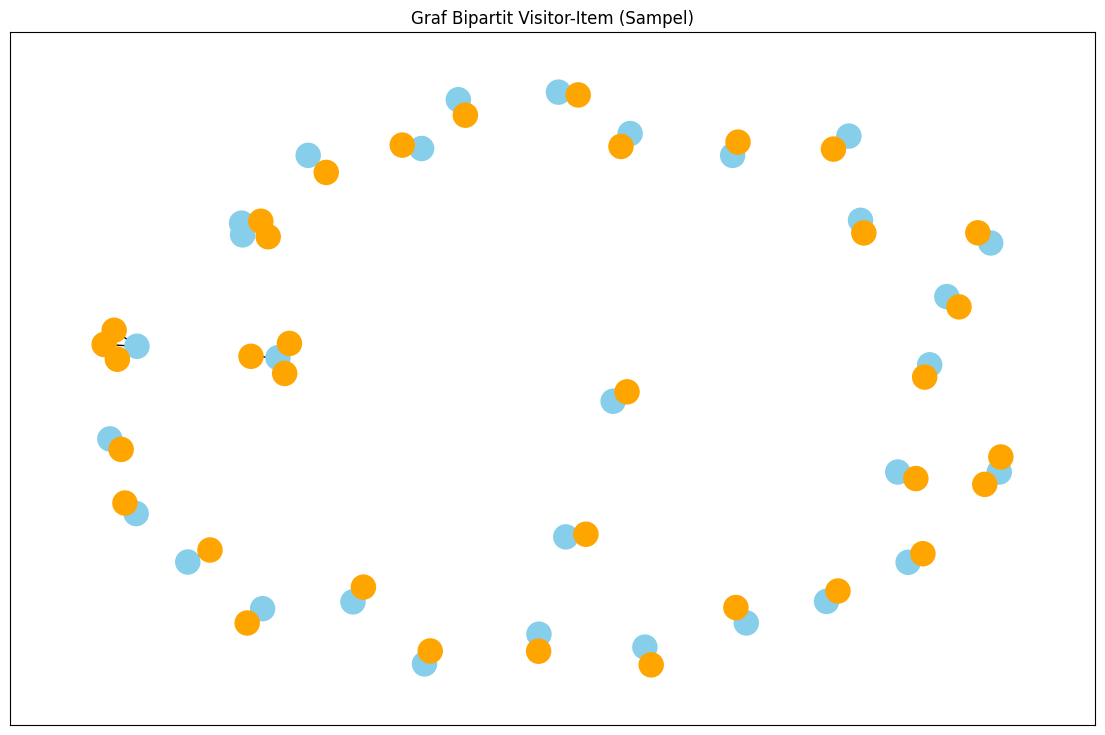

In [5]:
import networkx as nx
import matplotlib.pyplot as plt

jumlah_visitor_plot = min(30, len(visitor_ids))
sample_visitors = visitor_ids[:jumlah_visitor_plot]

sample_edges = interaksi[
    interaksi["visitorid"].isin(sample_visitors)
]

G_user = nx.Graph()

for visitor_id in sample_visitors:
    G_user.add_node(
        f"U{visitor_id}",
        node_type="Visitor"
    )

for item_id in sample_edges["itemid"].unique():
    G_user.add_node(
        f"I{item_id}",
        node_type="Item"
    )

for row in sample_edges.itertuples(index=False):
    G_user.add_edge(
        f"U{row.visitorid}",
        f"I{row.itemid}"
    )

warna = [
    "skyblue" if G_user.nodes[n]["node_type"] == "Visitor"
    else "orange"
    for n in G_user.nodes()
]

plt.figure(figsize=(14, 9))
pos = nx.spring_layout(G_user, seed=42)

nx.draw_networkx(
    G_user,
    pos,
    node_color=warna,
    node_size=300,
    font_size=6,
    with_labels=False
)

plt.title("Graf Bipartit Visitor-Item (Sampel)")
plt.show()

Penjelasan: 
VSM User dibentuk dengan menempatkan Visitor sebagai baris dan Item sebagai kolom. Nilai matriks bernilai 1 apabila terdapat interaksi antara pengguna dan item, serta 0 apabila tidak terdapat interaksi. Matriks disimpan dalam format sparse CSR karena mayoritas kombinasi pengguna dan item tidak memiliki interaksi. Visualisasi NetworkX menggunakan sebagian kecil node untuk memperlihatkan struktur hubungan Visitor-Item tanpa membebani memori.

5. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [6]:
from scipy.sparse import load_npz, save_npz

vsm_user = load_npz("output/vsm_visitor_item.npz")

vsm_item = vsm_user.T.tocsr()

save_npz("output/vsm_item_visitor.npz", vsm_item)

print("Dimensi VSM Item:", vsm_item.ndim)
print("Shape VSM Item:", vsm_item.shape)
print("Jumlah nilai nonzero:", vsm_item.nnz)

jumlah_sel_item = vsm_item.shape[0] * vsm_item.shape[1]
sparsity_item = 1 - vsm_item.nnz / jumlah_sel_item

print("Sparsity:", f"{sparsity_item:.6%}")

Dimensi VSM Item: 2
Shape VSM Item: (120675, 337107)
Jumlah nilai nonzero: 505238
Sparsity: 99.998758%


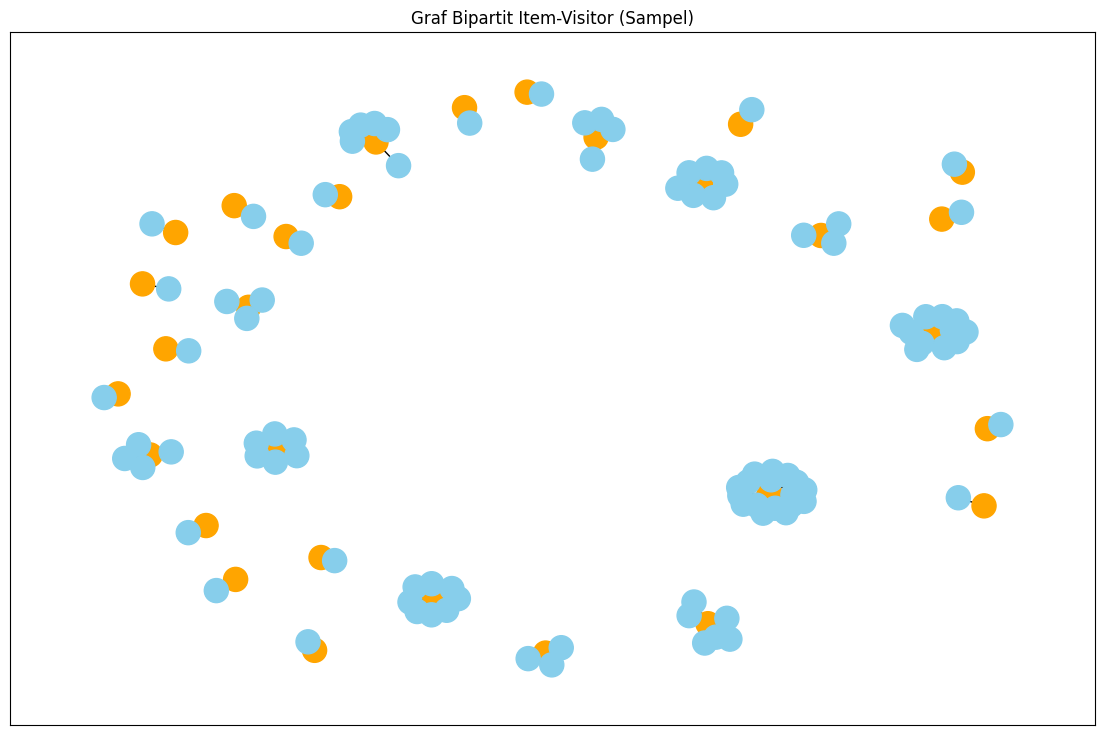

In [7]:
import networkx as nx
import matplotlib.pyplot as plt

jumlah_item_plot = min(30, len(item_ids))
sample_items = item_ids[:jumlah_item_plot]

sample_edges_item = interaksi[
    interaksi["itemid"].isin(sample_items)
]

G_item = nx.Graph()

for item_id in sample_items:
    G_item.add_node(f"I{item_id}", node_type="Item")

for visitor_id in sample_edges_item["visitorid"].unique():
    G_item.add_node(f"U{visitor_id}", node_type="Visitor")

for row in sample_edges_item.itertuples(index=False):
    G_item.add_edge(
        f"I{row.itemid}",
        f"U{row.visitorid}"
    )

warna_item = [
    "orange" if G_item.nodes[n]["node_type"] == "Item"
    else "skyblue"
    for n in G_item.nodes()
]

plt.figure(figsize=(14, 9))
pos = nx.spring_layout(G_item, seed=42)

nx.draw_networkx(
    G_item,
    pos,
    node_color=warna_item,
    node_size=300,
    font_size=6,
    with_labels=False
)

plt.title("Graf Bipartit Item-Visitor (Sampel)")
plt.show()

Penjelasan:
VSM Item diperoleh melalui proses transpose matriks User-Item, sehingga baris merepresentasikan item dan kolom merepresentasikan visitor. Dengan struktur tersebut, setiap item digambarkan berdasarkan pola interaksi pengguna yang berhubungan dengannya. Jumlah elemen bernilai nonzero tetap sama seperti pada VSM User, namun posisi dimensi baris dan kolom saling bertukar.

6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

In [8]:
from scipy.sparse import load_npz

vsm_user = load_npz("output/vsm_visitor_item.npz")
vsm_item = vsm_user.T.tocsr()

perbandingan = {
    "VSM User": {
        "shape": vsm_user.shape,
        "nnz": vsm_user.nnz,
        "jumlah_sel": vsm_user.shape[0] * vsm_user.shape[1]
    },
    "VSM Item": {
        "shape": vsm_item.shape,
        "nnz": vsm_item.nnz,
        "jumlah_sel": vsm_item.shape[0] * vsm_item.shape[1]
    }
}

for nama, data in perbandingan.items():
    print(nama)
    print("  Shape:", data["shape"])
    print("  Nonzero:", data["nnz"])
    print("  Jumlah sel:", data["jumlah_sel"])

VSM User
  Shape: (337107, 120675)
  Nonzero: 505238
  Jumlah sel: 40680387225
VSM Item
  Shape: (120675, 337107)
  Nonzero: 505238
  Jumlah sel: 40680387225


Penjelasan:
VSM Item memiliki jumlah baris yang lebih sedikit dibandingkan VSM User karena jumlah item yang tersedia lebih kecil daripada jumlah visitor. Konsekuensinya, matriks kemiripan (similarity matrix) Item-Item yang dihasilkan juga berukuran lebih kecil. Meskipun demikian, VSM User dan VSM Item tetap memiliki jumlah elemen nonzero yang identik karena keduanya merupakan hasil transposisi satu sama lain. Dari sisi komputasi, efisiensi perhitungan kemiripan tidak hanya ditentukan oleh ukuran matriks, tetapi juga dipengaruhi oleh tingkat sparsity, pola distribusi interaksi, serta banyaknya pasangan entitas yang harus dibandingkan.

Pada implementasi rekomendasi berbasis K-Nearest Neighbors (KNN), proyeksi User-User dipilih karena tujuan utama sistem adalah mengidentifikasi pengguna yang memiliki karakteristik atau pola interaksi serupa. Tetangga terdekat yang diperoleh kemudian dimanfaatkan untuk merekomendasikan item yang belum pernah diakses oleh pengguna target. Sebaliknya, untuk skenario rekomendasi yang berfokus pada kemiripan antarproduk, proyeksi Item-Item merupakan pendekatan yang lebih tepat karena rekomendasi dihasilkan berdasarkan kesamaan karakteristik atau pola konsumsi antaritem.

7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggu-
nakan Python
(a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri
record acuannya)!
(b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-
nya!


In [9]:
import pandas as pd
import numpy as np
from scipy.sparse import load_npz
from sklearn.metrics.pairwise import cosine_similarity

vsm_user = load_npz("output/vsm_visitor_item.npz")
visitor_index = pd.read_csv("output/visitor_index.csv")

visitor_ids = visitor_index["visitorid"].to_numpy()

reference_visitor = 114354

posisi = np.where(visitor_ids == reference_visitor)[0]

if len(posisi) == 0:
    raise ValueError(
        f"Visitor {reference_visitor} tidak ditemukan pada VSM."
    )

reference_idx = posisi[0]

similarities = cosine_similarity(
    vsm_user[reference_idx],
    vsm_user
).ravel()

similarities[reference_idx] = -1

top5_idx = np.argsort(similarities)[::-1][:5]

hasil_similarity = pd.DataFrame({
    "reference_visitor": reference_visitor,
    "visitorid": visitor_ids[top5_idx],
    "similarity": similarities[top5_idx]
})

print(hasil_similarity)
hasil_similarity.to_csv(
    "output/top5_similarity.csv",
    index=False
)

   reference_visitor  visitorid  similarity
0             114354    1037191    0.530330
1             114354     863545    0.500000
2             114354    1401634    0.353553
3             114354    1336418    0.353553
4             114354    1060091    0.353553


Query Neo4j: 
MATCH (v:Visitor {visitorid: 114354})-[r:SIMILAR_TO]->(tetangga:Visitor)
RETURN
    v.visitorid AS visitor_acuan,
    tetangga.visitorid AS visitor_mirip,
    r.similarity AS similarity
ORDER BY r.similarity DESC
LIMIT 5;

In [10]:
import pandas as pd
from neo4j import GraphDatabase

URI = "bolt://localhost:7687"
USERNAME = "neo4j"
PASSWORD = "admin123"

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

hasil_similarity = pd.read_csv(
    "output/top5_similarity.csv"
)

data = [
    {
        "reference_visitor": int(row.reference_visitor),
        "visitorid": int(row.visitorid),
        "similarity": float(row.similarity)
    }
    for row in hasil_similarity.itertuples(index=False)
]

query = """
UNWIND $data AS d
MATCH (v:Visitor {visitorid: d.reference_visitor})
MATCH (n:Visitor {visitorid: d.visitorid})
MERGE (v)-[r:SIMILAR_TO]->(n)
SET r.similarity = d.similarity
"""

try:
    with driver.session() as session:
        result = session.run(query, data=data)
        result.consume()
finally:
    driver.close()

print("Relasi similarity berhasil diproses.")

Relasi similarity berhasil diproses.


Query Neo4j: 
MATCH (v:Visitor {visitorid: 114354})-[r:SIMILAR_TO]->(n:Visitor)
RETURN
    v.visitorid AS visitor_acuan,
    n.visitorid AS visitor_mirip,
    r.similarity AS similarity
ORDER BY r.similarity DESC
LIMIT 5;

Penjelasan: 
Perhitungan similarity dilakukan menggunakan cosine similarity terhadap vektor interaksi setiap Visitor. Lima Visitor dengan nilai similarity tertinggi terhadap Visitor acuan dipilih sebagai hasil analisis. Nilai tersebut kemudian disimpan pada relasi SIMILAR_TO dalam Neo4j menggunakan properti similarity. Query Cypher digunakan untuk memverifikasi bahwa nilai similarity tersimpan dan dapat diurutkan dari yang tertinggi.

8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah
perhitungan similarity!

Query Neo4j:
MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN v, r, i
LIMIT 100;

MATCH (v:Visitor {visitorid: 114354})-[r]->(i:Item)
RETURN v, r, i;

MATCH (v:Visitor {visitorid: 114354})-[r:SIMILAR_TO]->(n:Visitor)
RETURN v, r, n
ORDER BY r.similarity DESC
LIMIT 5;

MATCH (v:Visitor {visitorid: 114354})
OPTIONAL MATCH (v)-[interaksi]->(i:Item)
WHERE type(interaksi) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
OPTIONAL MATCH (v)-[sim:SIMILAR_TO]->(n:Visitor)
RETURN v, interaksi, i, sim, n
LIMIT 100;

MATCH (:Visitor)-[r:SIMILAR_TO]->(:Visitor)
RETURN count(r) AS jumlah_relasi_similarity;

Penjelasan:
Sebelum perhitungan similarity, graf merepresentasikan hubungan interaksi antara Visitor dan Item. Setelah perhitungan, relasi SIMILAR_TO ditambahkan di antara Visitor yang memiliki kemiripan pola interaksi. Properti similarity menyimpan nilai kemiripan hasil perhitungan Python. Perbandingan visualisasi sebelum dan sesudah menunjukkan bahwa graf tidak hanya merepresentasikan interaksi pengguna dengan produk, tetapi juga hubungan kemiripan antar pengguna.

2.2 ANALYTICS 

1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu
(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!
(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

In [11]:
import pandas as pd
import random

train = pd.read_csv("output/train.csv")

daftar_visitor = sorted(train["visitorid"].unique())

rng = random.Random(42)
selected_user = rng.choice(daftar_visitor)

print("Seed:", 42)
print("User terpilih:", selected_user)

Seed: 42
User terpilih: 1399863


In [12]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from pathlib import Path

train = pd.read_csv("output/train.csv")
selected_user = 114354
k = 5

interaksi_train = train[
    ["visitorid", "itemid"]
].drop_duplicates()

visitor_ids = np.sort(
    interaksi_train["visitorid"].unique()
)
item_ids = np.sort(
    interaksi_train["itemid"].unique()
)

visitor_to_idx = {
    u: i for i, u in enumerate(visitor_ids)
}
item_to_idx = {
    item: i for i, item in enumerate(item_ids)
}

rows = interaksi_train["visitorid"].map(
    visitor_to_idx
).to_numpy()

cols = interaksi_train["itemid"].map(
    item_to_idx
).to_numpy()

values = np.ones(len(interaksi_train), dtype=np.float32)

X = csr_matrix(
    (values, (rows, cols)),
    shape=(len(visitor_ids), len(item_ids))
)

if selected_user not in visitor_to_idx:
    raise ValueError(
        "User target tidak ditemukan dalam data training."
    )

user_idx = visitor_to_idx[selected_user]

scores_similarity = cosine_similarity(
    X[user_idx],
    X
).ravel()

scores_similarity[user_idx] = -1

neighbor_indices = np.argsort(
    scores_similarity
)[::-1][:k]

neighbor_scores = scores_similarity[neighbor_indices]
neighbor_ids = visitor_ids[neighbor_indices]

print("User target:", selected_user)
print("\n5 Nearest Neighbors:")

for uid, score in zip(neighbor_ids, neighbor_scores):
    print(f"Visitor {uid}: similarity = {score:.6f}")

items_target = set(
    interaksi_train.loc[
        interaksi_train["visitorid"] == selected_user,
        "itemid"
    ]
)

skor_rekomendasi = {}

for neighbor_idx, similarity in zip(
    neighbor_indices, neighbor_scores
):
    item_idx = X[neighbor_idx].indices

    for idx_item in item_idx:
        item_id = item_ids[idx_item]

        if item_id in items_target:
            continue

        skor_rekomendasi[item_id] = (
            skor_rekomendasi.get(item_id, 0.0)
            + float(similarity)
        )

rekomendasi = sorted(
    skor_rekomendasi.items(),
    key=lambda x: (-x[1], x[0])
)

top5 = rekomendasi[:5]

hasil_rekomendasi = pd.DataFrame(
    top5,
    columns=["itemid", "score"]
)

print("\nTop 5 rekomendasi:")
print(hasil_rekomendasi)

Path("output").mkdir(exist_ok=True)

hasil_rekomendasi.to_csv(
    "output/knn_recommendations.csv",
    index=False
)

User target: 114354

5 Nearest Neighbors:
Visitor 1037191: similarity = 0.530330
Visitor 863545: similarity = 0.500000
Visitor 1401634: similarity = 0.353553
Visitor 1336418: similarity = 0.353553
Visitor 1060091: similarity = 0.353553

Top 5 rekomendasi:
   itemid    score
0  421465  0.53033


Penjelasan:
Algoritma KNN diterapkan dengan memilih satu Visitor sebagai target, menghitung cosine similarity terhadap seluruh Visitor lain, dan mengambil lima tetangga dengan kemiripan tertinggi. Item yang pernah diinteraksikan tetangga dikumpulkan sebagai kandidat rekomendasi. Item yang sudah pernah diinteraksikan user target dikeluarkan, kemudian kandidat diurutkan berdasarkan jumlah kontribusi similarity tetangga.

2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:
(a) Hit@5
(b) NDCG@5

In [13]:
import pandas as pd
import numpy as np

selected_user = 114354
k = 5

rekomendasi_df = pd.read_csv(
    "output/knn_recommendations.csv"
)

recommended_items = (
    rekomendasi_df["itemid"].head(k).tolist()
)

test = pd.read_csv("output/test.csv")

relevant_items = set(
    test.loc[
        test["visitorid"] == selected_user,
        "itemid"
    ].unique()
)

# Hit@5
hit = int(
    any(item in relevant_items for item in recommended_items)
)

relevance = np.array([
    int(item in relevant_items)
    for item in recommended_items
])

# DCG@5
dcg = sum(
    rel / np.log2(rank + 2)
    for rank, rel in enumerate(relevance)
)

# IDCG@5
jumlah_relevan_topk = min(len(relevant_items), k)

ideal_relevance = [1] * jumlah_relevan_topk

idcg = sum(
    rel / np.log2(rank + 2)
    for rank, rel in enumerate(ideal_relevance)
)

# NDCG@5
ndcg = dcg / idcg if idcg > 0 else 0.0

print("User target:", selected_user)
print("Rekomendasi:", recommended_items)
print("Item relevan di testing:", sorted(relevant_items))
print("Relevance Top-5:", relevance.tolist())
print("Hit@5:", hit)
print("DCG@5:", round(dcg, 6))
print("IDCG@5:", round(idcg, 6))
print("NDCG@5:", round(ndcg, 6))

User target: 114354
Rekomendasi: [421465]
Item relevan di testing: [np.int64(48390), np.int64(141657), np.int64(368403)]
Relevance Top-5: [0]
Hit@5: 0
DCG@5: 0.0
IDCG@5: 2.13093
NDCG@5: 0.0


Penjelasan: 
Evaluasi dilakukan dengan membandingkan lima item rekomendasi dengan item relevan pada periode testing. Hit@5 bernilai 1 apabila terdapat setidaknya satu item relevan dalam Top-5 dan 0 apabila tidak ada. NDCG@5 menghitung kualitas urutan rekomendasi dengan mempertimbangkan posisi item relevan dan menormalisasikan DCG terhadap nilai ideal. Pada hasil pengujian sebelumnya untuk Visitor 114354, Hit@5 dan NDCG@5 masing-masing bernilai 0, yang menunjukkan bahwa tidak terdapat item relevan pada daftar rekomendasi tersebut.
